In [1]:
# Cell 2 - Imports
import GEOparse
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [13]:
# Cell 4 - Fetch GSE6044 from GEO
GSE149507 = GEOparse.get_GEO(geo='GSE149507', destdir='./data/raw/', how='full')

05-Mar-2026 16:25:52 DEBUG utils - Directory ./data/raw/ already exists. Skipping.
05-Mar-2026 16:25:52 INFO GEOparse - Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE149nnn/GSE149507/soft/GSE149507_family.soft.gz to ./data/raw/GSE149507_family.soft.gz
100%|██████████| 6.23M/6.23M [00:09<00:00, 724kB/s] 
05-Mar-2026 16:26:03 DEBUG downloader - Size validation passed
05-Mar-2026 16:26:03 DEBUG downloader - Moving C:\Users\acer\AppData\Local\Temp\tmpjvybxk83 to C:\Users\acer\SCLC Project\data\raw\GSE149507_family.soft.gz
05-Mar-2026 16:26:03 DEBUG downloader - Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE149nnn/GSE149507/soft/GSE149507_family.soft.gz
05-Mar-2026 16:26:03 INFO GEOparse - Parsing ./data/raw/GSE149507_family.soft.gz: 
05-Mar-2026 16:26:03 DEBUG GEOparse - DATABASE: GeoMiame
05-Mar-2026 16:26:03 DEBUG GEOparse - SERIES: GSE149507
05-Mar-2026 16:26:03 DEBUG GEOparse - PLATFORM: GPL23270
05-Mar-2026 16:26:03 DEBUG GEOparse - SAMPLE: GSM4504101
05-Mar-

In [15]:
print(GSE149507.metadata)

{'title': ['Microarray expression data of 18 pairs of small cell lung cancer (sclc) and tumor and adjacent lung tissues'], 'geo_accession': ['GSE149507'], 'status': ['Public on Dec 29 2020'], 'submission_date': ['Apr 28 2020'], 'last_update_date': ['Mar 30 2021'], 'pubmed_id': ['33750914'], 'summary': ['Samples were collected from surgery resection'], 'overall_design': ['18 pairs of small cell lung cancer tumor and adjacent lung tissues were obtained from surgical resection. Gene expression profiling was performed by microarray.'], 'type': ['Expression profiling by array'], 'contributor': ['Hongyu,,Liu', 'Ling,,Cai'], 'sample_id': ['GSM4504101', 'GSM4504102', 'GSM4504103', 'GSM4504104', 'GSM4504105', 'GSM4504106', 'GSM4504107', 'GSM4504108', 'GSM4504109', 'GSM4504110', 'GSM4504111', 'GSM4504112', 'GSM4504113', 'GSM4504114', 'GSM4504115', 'GSM4504116', 'GSM4504117', 'GSM4504118', 'GSM4504119', 'GSM4504120', 'GSM4504121', 'GSM4504122', 'GSM4504123', 'GSM4504124', 'GSM4504125', 'GSM450412

In [17]:
# Cell 6 - Inspect samples
for gsm_name, gsm in GSE149507.gsms.items():
    print(gsm_name, gsm.metadata['title'])

GSM4504101 ['SCLC_01_ca']
GSM4504102 ['SCLC_01_n']
GSM4504103 ['SCLC_02_ca']
GSM4504104 ['SCLC_02_n']
GSM4504105 ['SCLC_03_ca']
GSM4504106 ['SCLC_03_n']
GSM4504107 ['SCLC_04_ca']
GSM4504108 ['SCLC_04_n']
GSM4504109 ['SCLC_05_ca']
GSM4504110 ['SCLC_05_n']
GSM4504111 ['SCLC_06_ca']
GSM4504112 ['SCLC_06_n']
GSM4504113 ['SCLC_07_ca']
GSM4504114 ['SCLC_07_n']
GSM4504115 ['SCLC_08_ca']
GSM4504116 ['SCLC_08_n']
GSM4504117 ['SCLC_09_ca']
GSM4504118 ['SCLC_09_n']
GSM4504119 ['SCLC_10_ca']
GSM4504120 ['SCLC_10_n']
GSM4504121 ['SCLC_11_ca']
GSM4504122 ['SCLC_11_n']
GSM4504123 ['SCLC_13_ca']
GSM4504124 ['SCLC_13_n']
GSM4504125 ['SCLC_14_ca']
GSM4504126 ['SCLC_14_n']
GSM4504127 ['SCLC_15_ca']
GSM4504128 ['SCLC_15_n']
GSM4504129 ['SCLC_16_ca']
GSM4504130 ['SCLC_16_n']
GSM4504131 ['SCLC_18_ca']
GSM4504132 ['SCLC_18_n']
GSM4504133 ['SCLC_19_ca']
GSM4504134 ['SCLC_19_n']
GSM4504135 ['SCLC_20_ca']
GSM4504136 ['SCLC_20_n']


In [21]:
# Cell 7 - Inspect a single sample to understand data structure
sample = list(GSE149507.gsms.values())[0]
print(sample.table.head())
print(sample.table.shape)

     ID_REF     VALUE
0      1_at  6.809986
1     10_at  4.087114
2    100_at  8.641343
3   1000_at  9.243192
4  10000_at  6.278093
(20425, 2)


In [25]:
# Cell 8 - Build expression matrix for SCLC and Normal samples only
samples_of_interest = {}

for gsm_id, gsm in GSE149507.gsms.items():
    title = gsm.metadata['title'][0]
    if '_ca' in title:
        samples_of_interest[gsm_id] = 'SCLC'
    elif '_n' in title:
        samples_of_interest[gsm_id] = 'Normal'

print('Selected samples:')
for gsm_id, group in samples_of_interest.items():
    print(f' {gsm_id}: {group}')

print(f'\nTotal: {len(samples_of_interest)}samples')

Selected samples:
 GSM4504101: SCLC
 GSM4504102: Normal
 GSM4504103: SCLC
 GSM4504104: Normal
 GSM4504105: SCLC
 GSM4504106: Normal
 GSM4504107: SCLC
 GSM4504108: Normal
 GSM4504109: SCLC
 GSM4504110: Normal
 GSM4504111: SCLC
 GSM4504112: Normal
 GSM4504113: SCLC
 GSM4504114: Normal
 GSM4504115: SCLC
 GSM4504116: Normal
 GSM4504117: SCLC
 GSM4504118: Normal
 GSM4504119: SCLC
 GSM4504120: Normal
 GSM4504121: SCLC
 GSM4504122: Normal
 GSM4504123: SCLC
 GSM4504124: Normal
 GSM4504125: SCLC
 GSM4504126: Normal
 GSM4504127: SCLC
 GSM4504128: Normal
 GSM4504129: SCLC
 GSM4504130: Normal
 GSM4504131: SCLC
 GSM4504132: Normal
 GSM4504133: SCLC
 GSM4504134: Normal
 GSM4504135: SCLC
 GSM4504136: Normal

Total: 36samples


In [27]:
# Cell 9 - Inspect platform annotation
platform = list(GSE149507.gpls.values())[0]
print(platform.table.head())
print(platform.table.columns.tolist())

         ID  ENTREZ_GENE_ID                    Description SPOT_ID
0      1_at             1.0         alpha-1-B glycoprotein     NaN
1     10_at            10.0          N-acetyltransferase 2     NaN
2    100_at           100.0            adenosine deaminase     NaN
3   1000_at          1000.0                     cadherin 2     NaN
4  10000_at         10000.0  AKT serine/threonine kinase 3     NaN
['ID', 'ENTREZ_GENE_ID', 'Description', 'SPOT_ID']


this data set has entrez_id instead of gene symbol so we have to get mygene pacakge to map the id to the gene

In [34]:
!pip install mygene==3.2.2

In [32]:
pip show mygene

Name: mygene
Version: 3.2.2
Summary: Python Client for MyGene.Info services.
Home-page: https://github.com/biothings/mygene.py
Author: Chunlei Wu, Cyrus Afrasiabi, Sebastien Lelong
Author-email: cwu@scripps.edu
License: BSD
Location: D:\Anaconda\Lib\site-packages
Requires: biothings-client
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [55]:
# mapping the entrez id to gene symbol
import mygene
mg = mygene.MyGeneInfo()

# Extract entrez ids from platform table
entrez_ids =  platform.table['ENTREZ_GENE_ID'].dropna().astype(int).tolist()

# Query Gene symbols
results = mg.querymany(entrez_ids, scopes='entrezgene', fields='symbol', species='human', as_dataframe=True)
print(results.head())

Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
191 input query terms found no hit:	['100129476', '100129503', '100130502', '100131096', '100505650', '100505728', '100506114', '1005065


         _id     _score symbol notfound
query                                  
1          1  26.576290   A1BG      NaN
10        10  27.367392   NAT2      NaN
100      100  26.578259    ADA      NaN
1000    1000  26.580606   CDH2      NaN
10000  10000  26.578259   AKT3      NaN


In [41]:
print(results.shape)

(20363, 4)


In [57]:
#renaming symbol to Gene Symbol for consistency
results = results.rename(columns={'symbol': 'Gene Symbol'})

In [59]:
# checking how many genes were not found
print(f"Total genes: {len(results)}")
print(f"Not found: {results['notfound'].notna().sum()}")
print(f"Successfully mapped: {results['notfound'].isna().sum()}")

Total genes: 20363
Not found: 191
Successfully mapped: 20172


In [61]:
#removing the suffix _at because entrez id in the results don't have them
platform.table['ID'].str.replace('_at', '', regex=False)

0                   1
1                  10
2                 100
3                1000
4               10000
             ...     
20420     AFFX-ThrX-5
20421     AFFX-ThrX-M
20422    AFFX-TrpnX-3
20423    AFFX-TrpnX-5
20424    AFFX-TrpnX-M
Name: ID, Length: 20425, dtype: object

In [73]:
# Cell 10 - Build annotated expression matrix
# Step 1 - Build raw matrix
expr_matrix = pd.DataFrame()
for gsm_id in samples_of_interest.keys():
    sample = GSE149507.gsms[gsm_id]
    df = sample.table.set_index('ID_REF')['VALUE']
    df.name = gsm_id
    expr_matrix = pd.concat([expr_matrix, df], axis=1)

# Step 2 - Get annotation from mygene results
annotation = results[['Gene Symbol']].copy()
annotation = annotation[annotation['Gene Symbol'].notna()]
annotation = annotation[annotation['Gene Symbol'] != '']

# Step 3 - Strip _at suffix from expr_matrix index to match results index
expr_matrix.index = expr_matrix.index.str.replace('_at', '', regex=False)

# Step 4 - Remove duplicate indices
annotation = annotation[~annotation.index.duplicated(keep='first')]

# Step 5 - Merge
expr_matrix.index.name = 'ID'
expr_matrix = expr_matrix.merge(annotation, left_index=True, right_index=True)
expr_matrix = expr_matrix.set_index('Gene Symbol')

# Step 6 - Collapse duplicates by mean
expr_matrix = expr_matrix.groupby('Gene Symbol').mean()

print(expr_matrix.shape)
print(expr_matrix.head())

(20172, 36)
             GSM4504101  GSM4504102  GSM4504103  GSM4504104  GSM4504105  \
Gene Symbol                                                               
A1BG           6.809986    5.673036    5.735682    6.559879    6.114000   
A1BG-AS1       4.784581    4.773959    4.960913    5.364942    4.966963   
A1CF           3.015293    2.749190    2.931073    2.728181    2.905942   
A2M           11.504035   13.686380   12.620901   13.736107   11.667369   
A2M-AS1        4.042309    6.339163    5.388992    6.906670    5.582117   

             GSM4504106  GSM4504107  GSM4504108  GSM4504109  GSM4504110  ...  \
Gene Symbol                                                              ...   
A1BG           5.663518    7.433055    5.993249    5.696446    5.557961  ...   
A1BG-AS1       5.073089    5.209064    5.045951    5.884313    5.105027  ...   
A1CF           2.854702    2.761648    2.754853    2.736425    2.840220  ...   
A2M           13.686380   10.559629   13.278119   10.427100   

we did not need to remove multi gene since 1 entrez id only give 1 gene symbol and any multiple genes are collasped during the mean step

In [82]:
# Cell 11 - Check for NA values
print(f'Total NA values: {expr_matrix.isna().sum().sum()}')
print(f'\nNa value per sample:')
print(expr_matrix.isna().sum())

Total NA values: 0

Na value per sample:
GSM4504101    0
GSM4504102    0
GSM4504103    0
GSM4504104    0
GSM4504105    0
GSM4504106    0
GSM4504107    0
GSM4504108    0
GSM4504109    0
GSM4504110    0
GSM4504111    0
GSM4504112    0
GSM4504113    0
GSM4504114    0
GSM4504115    0
GSM4504116    0
GSM4504117    0
GSM4504118    0
GSM4504119    0
GSM4504120    0
GSM4504121    0
GSM4504122    0
GSM4504123    0
GSM4504124    0
GSM4504125    0
GSM4504126    0
GSM4504127    0
GSM4504128    0
GSM4504129    0
GSM4504130    0
GSM4504131    0
GSM4504132    0
GSM4504133    0
GSM4504134    0
GSM4504135    0
GSM4504136    0
dtype: int64


In [84]:
expr_matrix.to_csv('./data/processed/GSE149507_expression_matrix.csv')
print('Expression matirx saved!')

Expression matirx saved!


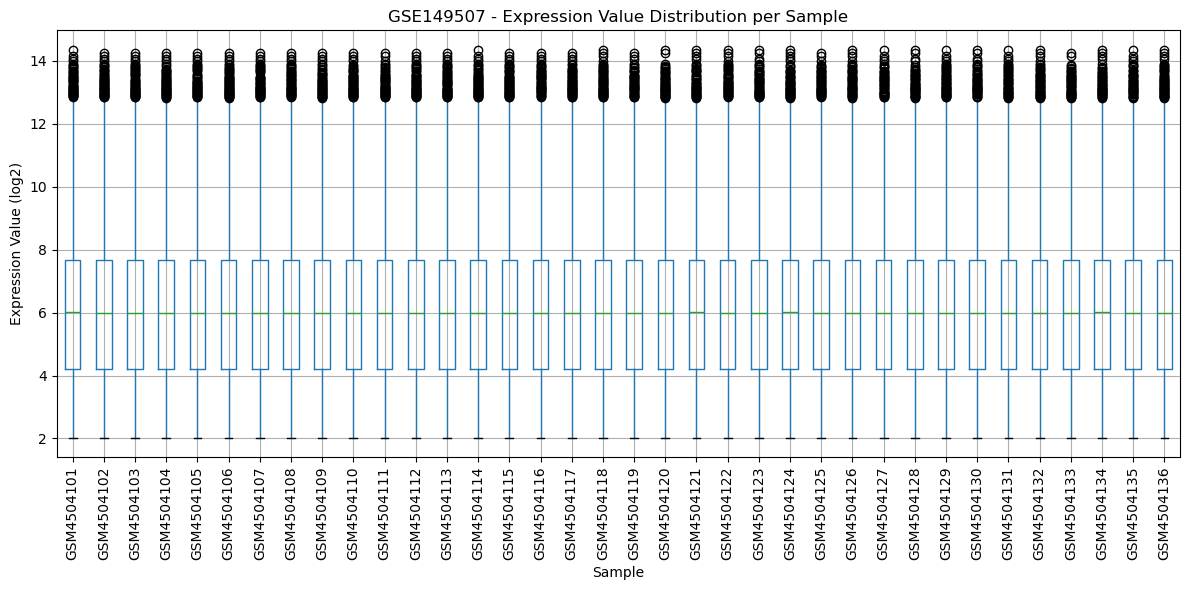

In [86]:
# Cell 13 - Sample distribution boxplot
plt.figure(figsize=(12, 6))
expr_matrix.boxplot(rot=90)
plt.title('GSE149507 - Expression Value Distribution per Sample')
plt.ylabel('Expression Value (log2)')
plt.xlabel('Sample')
plt.tight_layout()
plt.savefig('./figures/GSE149507_boxplot.png', dpi=300)
plt.show()

In [88]:
# Cell 14 - Create metadata dataframe
metadata = pd.DataFrame({
    'sample_id' : list(samples_of_interest.keys()),
    'group': list(samples_of_interest.values())
})
metadata = metadata.set_index('sample_id')
metadata.to_csv('./data/metadata/GSE149507_metadata.csv')
print(metadata)

             group
sample_id         
GSM4504101    SCLC
GSM4504102  Normal
GSM4504103    SCLC
GSM4504104  Normal
GSM4504105    SCLC
GSM4504106  Normal
GSM4504107    SCLC
GSM4504108  Normal
GSM4504109    SCLC
GSM4504110  Normal
GSM4504111    SCLC
GSM4504112  Normal
GSM4504113    SCLC
GSM4504114  Normal
GSM4504115    SCLC
GSM4504116  Normal
GSM4504117    SCLC
GSM4504118  Normal
GSM4504119    SCLC
GSM4504120  Normal
GSM4504121    SCLC
GSM4504122  Normal
GSM4504123    SCLC
GSM4504124  Normal
GSM4504125    SCLC
GSM4504126  Normal
GSM4504127    SCLC
GSM4504128  Normal
GSM4504129    SCLC
GSM4504130  Normal
GSM4504131    SCLC
GSM4504132  Normal
GSM4504133    SCLC
GSM4504134  Normal
GSM4504135    SCLC
GSM4504136  Normal


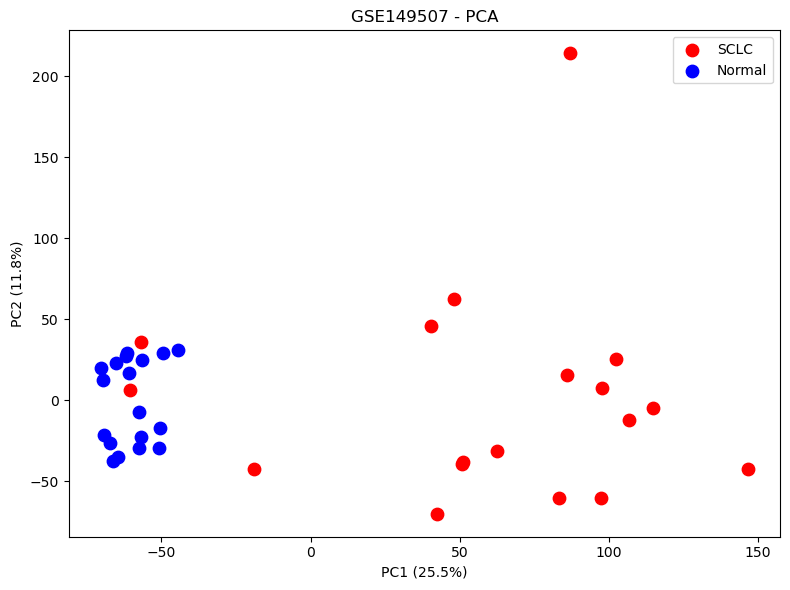

In [92]:
# Cell 15 - PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Standardize the data
scaler = StandardScaler()
expr_scaled = scaler.fit_transform(expr_matrix.T)

# Run PCA
pca = PCA(n_components=2)
pca_coords = pca.fit_transform(expr_scaled)

# Plot
plt.figure(figsize=(8, 6))
colors = {'SCLC': 'red', 'Normal': 'blue'}
for group in ['SCLC', 'Normal']:
    mask = metadata['group'] == group
    plt.scatter(pca_coords[mask, 0], pca_coords[mask, 1],
                c=colors[group], label=group, s=80)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('GSE149507 - PCA')
plt.legend()
plt.tight_layout()
plt.savefig('./figures/GSE149507_PCA.png', dpi=300)
plt.show()

In [94]:
# Sanity checks
print(f"Expected samples: 36, Got: {expr_matrix.shape[1]}")
print(f"Expected genes: 20172, Got: {expr_matrix.shape[0]}")
print(f"NA values: {expr_matrix.isna().sum().sum()}")
print(f"\nSample groups:")
print(metadata['group'].value_counts())
print(f"\nAny duplicate gene symbols: {expr_matrix.index.duplicated().sum()}")

Expected samples: 36, Got: 36
Expected genes: 20172, Got: 20172
NA values: 0

Sample groups:
group
SCLC      18
Normal    18
Name: count, dtype: int64

Any duplicate gene symbols: 0


In [96]:
# investigation into the 3 sclc samples closest to normal cluster
pca_df = pd.DataFrame(pca_coords, index=metadata.index, columns=['PC1', 'PC2'])
sclc_samples = metadata[metadata['group'] == 'SCLC'].index
pca_sclc = pca_df.loc[sclc_samples]
# Find SCLC samples with positive PC1 (Normal side)
suspicious = pca_sclc[pca_sclc['PC1'] < 0]
print(suspicious)

                  PC1        PC2
sample_id                       
GSM4504115 -56.786069  35.903741
GSM4504117 -60.553131   6.308637
GSM4504121 -18.992012 -42.122083


In [98]:
for gsm_id in ['GSM4504115', 'GSM4504117', 'GSM4504121']:
    meta = GSE149507.gsms[gsm_id].metadata
    print(f"\n--- {gsm_id} ---")
    print(f"Title: {meta['title']}")
    print(f"Characteristics: {meta.get('characteristics_ch1', 'N/A')}")


--- GSM4504115 ---
Title: ['SCLC_08_ca']
Characteristics: ['tissue: small cell lung cancer tumor', 'gender: M', 'age: 57', 'smoking_status: Ever', 'tobacco_pack_per_day: 1', 'smoking_years: 20', 'tnm_stage: T4N2M0', 'neoadjuvant: NA']

--- GSM4504117 ---
Title: ['SCLC_09_ca']
Characteristics: ['tissue: small cell lung cancer tumor', 'gender: F', 'age: 48', 'smoking_status: NA', 'tobacco_pack_per_day: NA', 'smoking_years: NA', 'tnm_stage: T1N1M0', 'neoadjuvant: YES']

--- GSM4504121 ---
Title: ['SCLC_11_ca']
Characteristics: ['tissue: small cell lung cancer tumor', 'gender: F', 'age: 65', 'smoking_status: Ever', 'tobacco_pack_per_day: 1', 'smoking_years: 20', 'tnm_stage: T2N2M0', 'neoadjuvant: NO']


In [100]:
for gsm_id, gsm in GSE149507.gsms.items():
    chars = gsm.metadata.get('characteristics_ch1', [])
    neoadjuvant = [c for c in chars if 'neoadjuvant' in c.lower()]
    if neoadjuvant:
        print(f"{gsm_id}: {gsm.metadata['title']} - {neoadjuvant}")

GSM4504101: ['SCLC_01_ca'] - ['neoadjuvant: NA']
GSM4504102: ['SCLC_01_n'] - ['neoadjuvant: NA']
GSM4504103: ['SCLC_02_ca'] - ['neoadjuvant: NO']
GSM4504104: ['SCLC_02_n'] - ['neoadjuvant: NO']
GSM4504105: ['SCLC_03_ca'] - ['neoadjuvant: NO']
GSM4504106: ['SCLC_03_n'] - ['neoadjuvant: NO']
GSM4504107: ['SCLC_04_ca'] - ['neoadjuvant: NO']
GSM4504108: ['SCLC_04_n'] - ['neoadjuvant: NO']
GSM4504109: ['SCLC_05_ca'] - ['neoadjuvant: YES']
GSM4504110: ['SCLC_05_n'] - ['neoadjuvant: YES']
GSM4504111: ['SCLC_06_ca'] - ['neoadjuvant: NA']
GSM4504112: ['SCLC_06_n'] - ['neoadjuvant: NA']
GSM4504113: ['SCLC_07_ca'] - ['neoadjuvant: NO']
GSM4504114: ['SCLC_07_n'] - ['neoadjuvant: NO']
GSM4504115: ['SCLC_08_ca'] - ['neoadjuvant: NA']
GSM4504116: ['SCLC_08_n'] - ['neoadjuvant: NA']
GSM4504117: ['SCLC_09_ca'] - ['neoadjuvant: YES']
GSM4504118: ['SCLC_09_n'] - ['neoadjuvant: YES']
GSM4504119: ['SCLC_10_ca'] - ['neoadjuvant: NO']
GSM4504120: ['SCLC_10_n'] - ['neoadjuvant: NO']
GSM4504121: ['SCLC_11_ca']

In [102]:
samples_of_interest = {}

for gsm_id, gsm in GSE149507.gsms.items():
    title = gsm.metadata['title'][0]
    chars = gsm.metadata.get('characteristics_ch1', [])
    neoadjuvant = [c for c in chars if 'neoadjuvant' in c.lower()]
    
    # Skip neoadjuvant YES samples
    if any('YES' in c for c in neoadjuvant):
        continue
        
    if '_ca' in title:
        samples_of_interest[gsm_id] = 'SCLC'
    elif '_n' in title:
        samples_of_interest[gsm_id] = 'Normal'

print("Selected samples:")
for gsm_id, group in samples_of_interest.items():
    print(f" {gsm_id}: {group}")
print(f"\nTotal: {len(samples_of_interest)} samples")

Selected samples:
 GSM4504101: SCLC
 GSM4504102: Normal
 GSM4504103: SCLC
 GSM4504104: Normal
 GSM4504105: SCLC
 GSM4504106: Normal
 GSM4504107: SCLC
 GSM4504108: Normal
 GSM4504111: SCLC
 GSM4504112: Normal
 GSM4504113: SCLC
 GSM4504114: Normal
 GSM4504115: SCLC
 GSM4504116: Normal
 GSM4504119: SCLC
 GSM4504120: Normal
 GSM4504121: SCLC
 GSM4504122: Normal
 GSM4504123: SCLC
 GSM4504124: Normal
 GSM4504125: SCLC
 GSM4504126: Normal
 GSM4504127: SCLC
 GSM4504128: Normal
 GSM4504131: SCLC
 GSM4504132: Normal
 GSM4504133: SCLC
 GSM4504134: Normal
 GSM4504135: SCLC
 GSM4504136: Normal

Total: 30 samples


In [104]:
# Cell 10 - Build annotated expression matrix
# Step 1 - Build raw matrix
expr_matrix = pd.DataFrame()
for gsm_id in samples_of_interest.keys():
    sample = GSE149507.gsms[gsm_id]
    df = sample.table.set_index('ID_REF')['VALUE']
    df.name = gsm_id
    expr_matrix = pd.concat([expr_matrix, df], axis=1)

# Step 2 - Get annotation from mygene results
annotation = results[['Gene Symbol']].copy()
annotation = annotation[annotation['Gene Symbol'].notna()]
annotation = annotation[annotation['Gene Symbol'] != '']

# Step 3 - Strip _at suffix from expr_matrix index to match results index
expr_matrix.index = expr_matrix.index.str.replace('_at', '', regex=False)

# Step 4 - Remove duplicate indices
annotation = annotation[~annotation.index.duplicated(keep='first')]

# Step 5 - Merge
expr_matrix.index.name = 'ID'
expr_matrix = expr_matrix.merge(annotation, left_index=True, right_index=True)
expr_matrix = expr_matrix.set_index('Gene Symbol')

# Step 6 - Collapse duplicates by mean
expr_matrix = expr_matrix.groupby('Gene Symbol').mean()

print(expr_matrix.shape)
print(expr_matrix.head())

(20172, 30)
             GSM4504101  GSM4504102  GSM4504103  GSM4504104  GSM4504105  \
Gene Symbol                                                               
A1BG           6.809986    5.673036    5.735682    6.559879    6.114000   
A1BG-AS1       4.784581    4.773959    4.960913    5.364942    4.966963   
A1CF           3.015293    2.749190    2.931073    2.728181    2.905942   
A2M           11.504035   13.686380   12.620901   13.736107   11.667369   
A2M-AS1        4.042309    6.339163    5.388992    6.906670    5.582117   

             GSM4504106  GSM4504107  GSM4504108  GSM4504111  GSM4504112  ...  \
Gene Symbol                                                              ...   
A1BG           5.663518    7.433055    5.993249    7.070435    5.683598  ...   
A1BG-AS1       5.073089    5.209064    5.045951    5.835385    5.100519  ...   
A1CF           2.854702    2.761648    2.754853    2.727293    3.163608  ...   
A2M           13.686380   10.559629   13.278119   11.699296   

In [114]:
# Cell 14 - Create metadata dataframe
metadata = pd.DataFrame({
    'sample_id' : list(samples_of_interest.keys()),
    'group': list(samples_of_interest.values())
})
metadata = metadata.set_index('sample_id')
metadata.to_csv('./data/metadata/GSE149507_filtered_metadata.csv')
print(metadata)

             group
sample_id         
GSM4504101    SCLC
GSM4504102  Normal
GSM4504103    SCLC
GSM4504104  Normal
GSM4504105    SCLC
GSM4504106  Normal
GSM4504107    SCLC
GSM4504108  Normal
GSM4504111    SCLC
GSM4504112  Normal
GSM4504113    SCLC
GSM4504114  Normal
GSM4504115    SCLC
GSM4504116  Normal
GSM4504119    SCLC
GSM4504120  Normal
GSM4504121    SCLC
GSM4504122  Normal
GSM4504123    SCLC
GSM4504124  Normal
GSM4504125    SCLC
GSM4504126  Normal
GSM4504127    SCLC
GSM4504128  Normal
GSM4504131    SCLC
GSM4504132  Normal
GSM4504133    SCLC
GSM4504134  Normal
GSM4504135    SCLC
GSM4504136  Normal


In [110]:
# Sanity checks
print(f"Expected samples: 30, Got: {expr_matrix.shape[1]}")
print(f"Expected genes: 20172, Got: {expr_matrix.shape[0]}")
print(f"NA values: {expr_matrix.isna().sum().sum()}")
print(f"\nSample groups:")
print(metadata['group'].value_counts())
print(f"\nAny duplicate gene symbols: {expr_matrix.index.duplicated().sum()}")

Expected samples: 30, Got: 30
Expected genes: 20172, Got: 20172
NA values: 0

Sample groups:
group
SCLC      15
Normal    15
Name: count, dtype: int64

Any duplicate gene symbols: 0


In [112]:
expr_matrix.to_csv('./data/processed/GSE149507_filtered_expression_matrix.csv')
print('Expression matirx saved!')

Expression matirx saved!


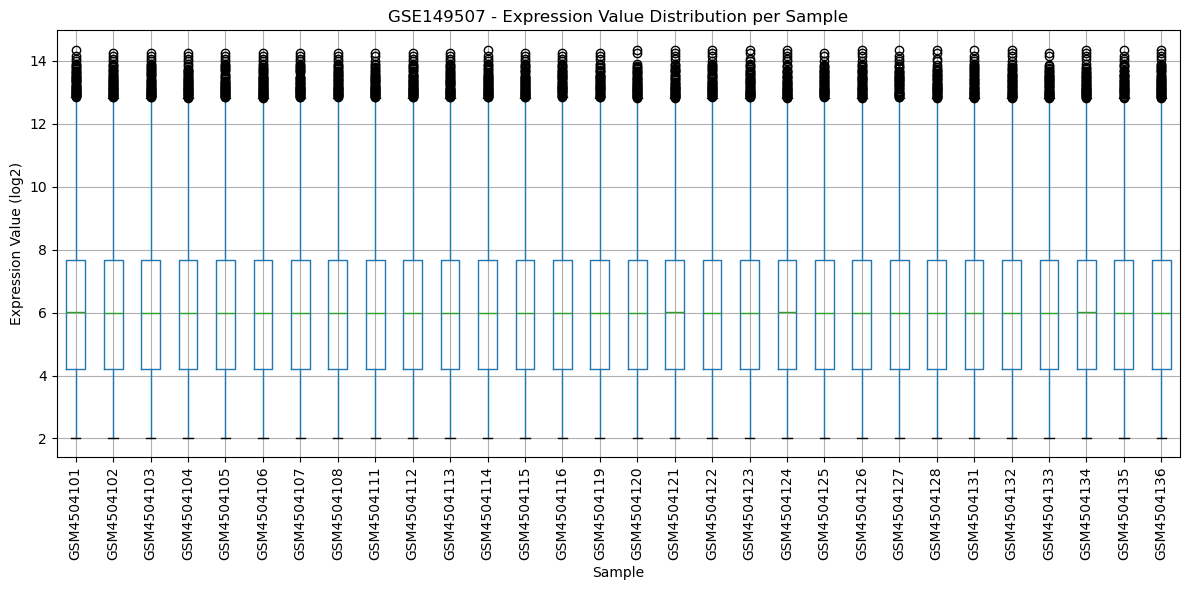

In [116]:
# Cell 13 - Sample distribution boxplot
plt.figure(figsize=(12, 6))
expr_matrix.boxplot(rot=90)
plt.title('GSE149507 - Expression Value Distribution per Sample')
plt.ylabel('Expression Value (log2)')
plt.xlabel('Sample')
plt.tight_layout()
plt.savefig('./figures/GSE149507_filtered_boxplot.png', dpi=300)
plt.show()

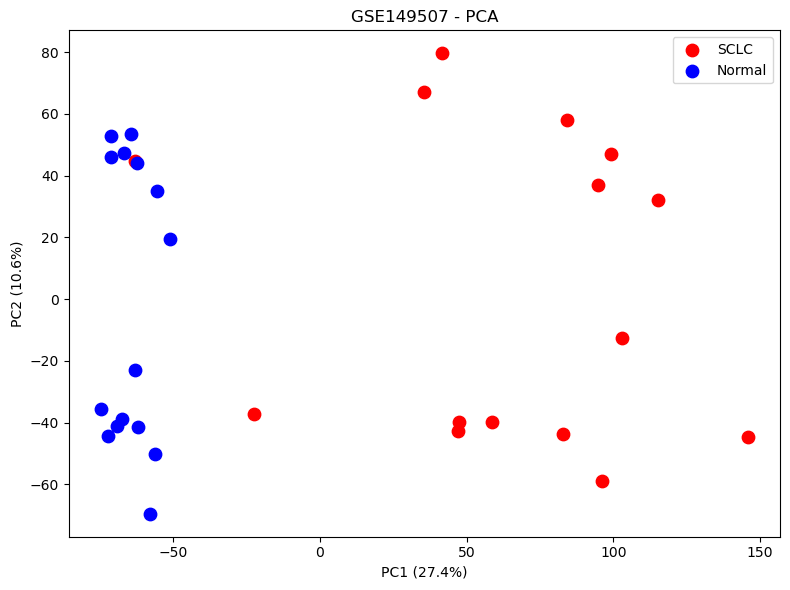

In [118]:
# Cell 15 - PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Standardize the data
scaler = StandardScaler()
expr_scaled = scaler.fit_transform(expr_matrix.T)

# Run PCA
pca = PCA(n_components=2)
pca_coords = pca.fit_transform(expr_scaled)

# Plot
plt.figure(figsize=(8, 6))
colors = {'SCLC': 'red', 'Normal': 'blue'}
for group in ['SCLC', 'Normal']:
    mask = metadata['group'] == group
    plt.scatter(pca_coords[mask, 0], pca_coords[mask, 1],
                c=colors[group], label=group, s=80)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('GSE149507 - PCA')
plt.legend()
plt.tight_layout()
plt.savefig('./figures/GSE149507_filtered_PCA.png', dpi=300)
plt.show()

In [120]:
print(GSE149507.gsms['GSM4504115'].metadata)
print(GSE149507.gsms['GSM4504116'].metadata)

{'title': ['SCLC_08_ca'], 'geo_accession': ['GSM4504115'], 'status': ['Public on Dec 29 2020'], 'submission_date': ['Apr 28 2020'], 'last_update_date': ['Dec 29 2020'], 'type': ['RNA'], 'channel_count': ['1'], 'source_name_ch1': ['tumor'], 'organism_ch1': ['Homo sapiens'], 'taxid_ch1': ['9606'], 'characteristics_ch1': ['tissue: small cell lung cancer tumor', 'gender: M', 'age: 57', 'smoking_status: Ever', 'tobacco_pack_per_day: 1', 'smoking_years: 20', 'tnm_stage: T4N2M0', 'neoadjuvant: NA'], 'molecule_ch1': ['total RNA'], 'extract_protocol_ch1': ['Not provided'], 'label_ch1': ['biotin'], 'label_protocol_ch1': ['Not provided'], 'hyb_protocol': ['Not provided'], 'scan_protocol': ['Not provided'], 'data_processing': ['CEL files were read into an AffyBatch object by AffyBatch function under the affy R package, alternative cdf package hgu133plus2hsentrezg was downloaded from http://mbni.org/customcdf/21.0.0/entrezg.download/hgu133plus2hsentrezg.db_21.0.0.zip and was specified in the functi

In [122]:
# Remove PCA outlier pair from samples_of_interest
samples_of_interest = {k: v for k, v in samples_of_interest.items() 
                       if k not in ['GSM4504115', 'GSM4504116']}

print(f"Total: {len(samples_of_interest)} samples")
print(f"SCLC: {list(samples_of_interest.values()).count('SCLC')}")
print(f"Normal: {list(samples_of_interest.values()).count('Normal')}")

Total: 28 samples
SCLC: 14
Normal: 14


In [124]:
# Cell 10 - Build annotated expression matrix
# Step 1 - Build raw matrix
expr_matrix = pd.DataFrame()
for gsm_id in samples_of_interest.keys():
    sample = GSE149507.gsms[gsm_id]
    df = sample.table.set_index('ID_REF')['VALUE']
    df.name = gsm_id
    expr_matrix = pd.concat([expr_matrix, df], axis=1)

# Step 2 - Get annotation from mygene results
annotation = results[['Gene Symbol']].copy()
annotation = annotation[annotation['Gene Symbol'].notna()]
annotation = annotation[annotation['Gene Symbol'] != '']

# Step 3 - Strip _at suffix from expr_matrix index to match results index
expr_matrix.index = expr_matrix.index.str.replace('_at', '', regex=False)

# Step 4 - Remove duplicate indices
annotation = annotation[~annotation.index.duplicated(keep='first')]

# Step 5 - Merge
expr_matrix.index.name = 'ID'
expr_matrix = expr_matrix.merge(annotation, left_index=True, right_index=True)
expr_matrix = expr_matrix.set_index('Gene Symbol')

# Step 6 - Collapse duplicates by mean
expr_matrix = expr_matrix.groupby('Gene Symbol').mean()

print(expr_matrix.shape)
print(expr_matrix.head())

(20172, 28)
             GSM4504101  GSM4504102  GSM4504103  GSM4504104  GSM4504105  \
Gene Symbol                                                               
A1BG           6.809986    5.673036    5.735682    6.559879    6.114000   
A1BG-AS1       4.784581    4.773959    4.960913    5.364942    4.966963   
A1CF           3.015293    2.749190    2.931073    2.728181    2.905942   
A2M           11.504035   13.686380   12.620901   13.736107   11.667369   
A2M-AS1        4.042309    6.339163    5.388992    6.906670    5.582117   

             GSM4504106  GSM4504107  GSM4504108  GSM4504111  GSM4504112  ...  \
Gene Symbol                                                              ...   
A1BG           5.663518    7.433055    5.993249    7.070435    5.683598  ...   
A1BG-AS1       5.073089    5.209064    5.045951    5.835385    5.100519  ...   
A1CF           2.854702    2.761648    2.754853    2.727293    3.163608  ...   
A2M           13.686380   10.559629   13.278119   11.699296   

In [126]:
expr_matrix.to_csv('./data/processed/GSE149507_filtered_expression_matrix_final.csv')
print('Expression matirx saved!')

Expression matirx saved!


In [128]:
# Cell 14 - Create metadata dataframe
metadata = pd.DataFrame({
    'sample_id' : list(samples_of_interest.keys()),
    'group': list(samples_of_interest.values())
})
metadata = metadata.set_index('sample_id')
metadata.to_csv('./data/metadata/GSE149507_filtered_metadata_final.csv')
print(metadata)

             group
sample_id         
GSM4504101    SCLC
GSM4504102  Normal
GSM4504103    SCLC
GSM4504104  Normal
GSM4504105    SCLC
GSM4504106  Normal
GSM4504107    SCLC
GSM4504108  Normal
GSM4504111    SCLC
GSM4504112  Normal
GSM4504113    SCLC
GSM4504114  Normal
GSM4504119    SCLC
GSM4504120  Normal
GSM4504121    SCLC
GSM4504122  Normal
GSM4504123    SCLC
GSM4504124  Normal
GSM4504125    SCLC
GSM4504126  Normal
GSM4504127    SCLC
GSM4504128  Normal
GSM4504131    SCLC
GSM4504132  Normal
GSM4504133    SCLC
GSM4504134  Normal
GSM4504135    SCLC
GSM4504136  Normal


In [132]:
# Sanity checks
print(f"Expected samples: 28, Got: {expr_matrix.shape[1]}")
print(f"Expected genes: 20172, Got: {expr_matrix.shape[0]}")
print(f"NA values: {expr_matrix.isna().sum().sum()}")
print(f"\nSample groups:")
print(metadata['group'].value_counts())
print(f"\nAny duplicate gene symbols: {expr_matrix.index.duplicated().sum()}")

Expected samples: 28, Got: 28
Expected genes: 20172, Got: 20172
NA values: 0

Sample groups:
group
SCLC      14
Normal    14
Name: count, dtype: int64

Any duplicate gene symbols: 0


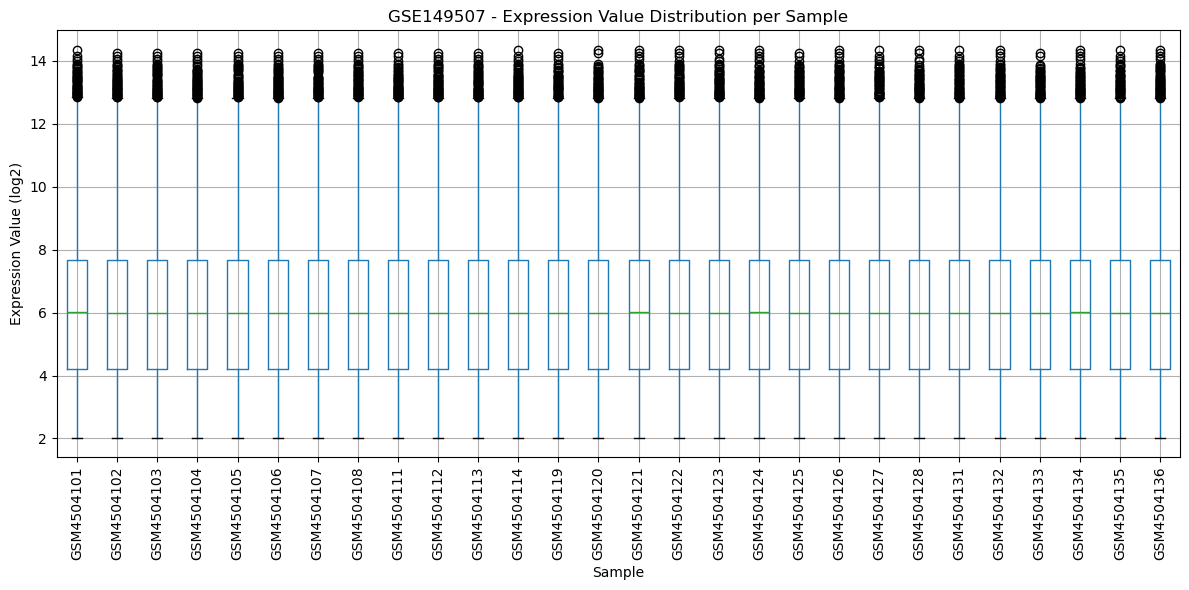

In [134]:
# Cell 13 - Sample distribution boxplot
plt.figure(figsize=(12, 6))
expr_matrix.boxplot(rot=90)
plt.title('GSE149507 - Expression Value Distribution per Sample')
plt.ylabel('Expression Value (log2)')
plt.xlabel('Sample')
plt.tight_layout()
plt.savefig('./figures/GSE149507_filtered_boxplot_final.png', dpi=300)
plt.show()

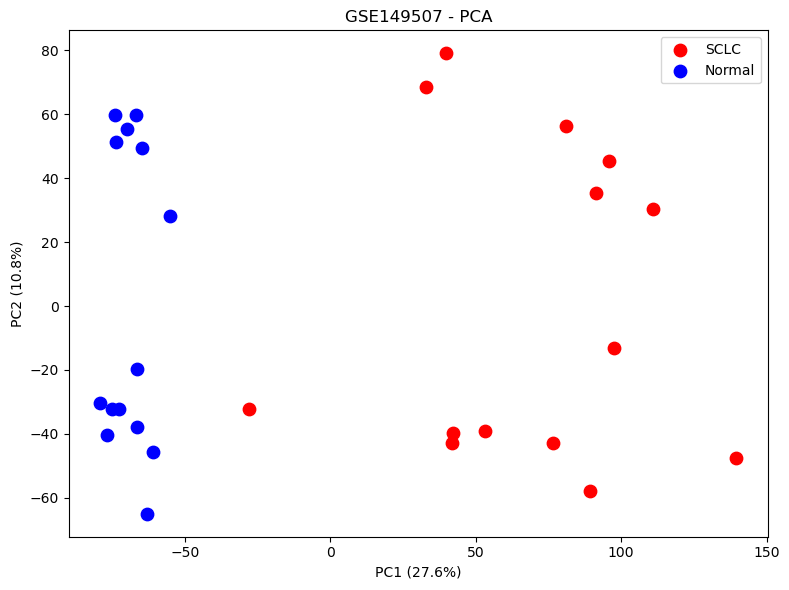

In [136]:
# Cell 15 - PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Standardize the data
scaler = StandardScaler()
expr_scaled = scaler.fit_transform(expr_matrix.T)

# Run PCA
pca = PCA(n_components=2)
pca_coords = pca.fit_transform(expr_scaled)

# Plot
plt.figure(figsize=(8, 6))
colors = {'SCLC': 'red', 'Normal': 'blue'}
for group in ['SCLC', 'Normal']:
    mask = metadata['group'] == group
    plt.scatter(pca_coords[mask, 0], pca_coords[mask, 1],
                c=colors[group], label=group, s=80)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('GSE149507 - PCA')
plt.legend()
plt.tight_layout()
plt.savefig('./figures/GSE149507_filtered_PCA_final.png', dpi=300)
plt.show()